<a href="https://colab.research.google.com/github/RichieBuilds/SemProject_MLEngine/blob/final/YOLO11s_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadWatch: YOLO11s Pothole Detection

We built RoadWatch's ML engine to locate potholes in road images. The final detector is YOLO11s fine-tuned for one class: pothole. For each candidate, it returns a bounding box and confidence score. It does not estimate pothole severity, geographic location, or repair cost.

This notebook brings together our data exploration, cleaned-v3 validation, training record, saved-model evaluation, and image inference. The original split appears only in the initial CSV exploration; model development and evaluation use cleaned-v3.

## Experiment environment and assets

We trained the cleaned-v3 YOLO11s model in Google Colab. The shared Drive folder contains the dataset archive in three numbered parts and the saved training run. The setup cell restores the repository and data, verifies the archive and checkpoint hashes, and sets the paths used by the remaining sections.

The source folder was shared with the group. In Colab it is mounted at `/content/drive/MyDrive/RoadWatch_cleaned_training` through a Drive shortcut, since the mounted `MyDrive` does not directly expose Shared with me. The saved checkpoint is under `pothole_yolo11s_cleaned_v3/weights/best.pt`.

In [2]:
# Restore the Colab environment, repository, cleaned data, and saved checkpoint.
import hashlib
import os
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path

subprocess.run([
    sys.executable, "-m", "pip", "install", "-q",
    "ultralytics==8.4.189", "pandas", "matplotlib", "pillow",
], check=True)

from google.colab import drive
drive.mount("/content/drive")

REPO_URL = "https://github.com/RichieBuilds/SemProject_MLEngine.git"
REPO_ROOT = Path("/content/SemProject_MLEngine")
if not REPO_ROOT.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_ROOT)], check=True)
os.chdir(REPO_ROOT)

DRIVE_ROOT = Path("/content/drive/MyDrive")
SHARED_ROOT = DRIVE_ROOT / "RoadWatch_cleaned_training"
if not SHARED_ROOT.is_dir():
    raise FileNotFoundError(
        "The shared RoadWatch_cleaned_training folder is not mounted in MyDrive. "
        "It must be available through a Drive shortcut."
    )

DATASET_SHA256 = "31fff83565a63da76e32419825cd8b613f5aac322ed00df62470b53f9bf4785e"
ARCHIVE = Path("/content/roadwatch_cleaned_v3.zip")
PARTS = [SHARED_ROOT / f"roadwatch_cleaned_v3.zip.part{i:03d}" for i in (1, 2, 3)]
if not ARCHIVE.is_file():
    full_archive = SHARED_ROOT / "roadwatch_cleaned_v3.zip"
    if full_archive.is_file():
        shutil.copyfile(full_archive, ARCHIVE)
    elif all(part.is_file() for part in PARTS):
        with ARCHIVE.open("wb") as output:
            for part in PARTS:
                with part.open("rb") as source:
                    shutil.copyfileobj(source, output)
    else:
        missing = [str(part) for part in PARTS if not part.is_file()]
        raise FileNotFoundError("Missing cleaned dataset ZIP parts: " + ", ".join(missing))

digest = hashlib.sha256()
with ARCHIVE.open("rb") as stream:
    for chunk in iter(lambda: stream.read(1024 * 1024), b""):
        digest.update(chunk)
if digest.hexdigest() != DATASET_SHA256:
    raise ValueError("The assembled cleaned-v3 archive checksum does not match the recorded dataset.")

DATA_ROOT = Path("/content/roadwatch_cleaned")
if not all((DATA_ROOT / split / "images").is_dir() for split in ("train", "valid", "test")):
    with zipfile.ZipFile(ARCHIVE) as archive:
        destination = DATA_ROOT.parent.resolve()
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(destination):
                raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
        archive.extractall(destination)
if not all((DATA_ROOT / split / "images").is_dir() for split in ("train", "valid", "test")):
    raise FileNotFoundError(f"Cleaned-v3 train, valid, and test folders were not found under {DATA_ROOT}")
os.environ["ROADWATCH_DATA_ROOT"] = str(DATA_ROOT)

CHECKPOINT_SHA256 = "9dad6abd86b08e02d76a02f5e0190ddf373b39de9b8487646f01a541e8810291"
RUN_FOLDER = SHARED_ROOT / "pothole_yolo11s_cleaned_v3"
CHECKPOINT = RUN_FOLDER / "weights" / "best.pt"
if not CHECKPOINT.is_file():
    matches = sorted(RUN_FOLDER.rglob("best.pt")) if RUN_FOLDER.is_dir() else []
    CHECKPOINT = matches[0] if matches else CHECKPOINT
if CHECKPOINT.is_file():
    checkpoint_digest = hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest()
    if checkpoint_digest != CHECKPOINT_SHA256:
        raise ValueError(f"Checkpoint checksum differs from the recorded cleaned-v3 model: {CHECKPOINT}")
    os.environ["ROADWATCH_MODEL"] = str(CHECKPOINT)
    print("Verified cleaned-v3 checkpoint:", CHECKPOINT)
else:
    print("No saved cleaned-v3 checkpoint was found in the mounted Drive folder.")
print("Repository:", REPO_ROOT)
print("Cleaned dataset:", DATA_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Verified cleaned-v3 checkpoint: /content/drive/MyDrive/RoadWatch_cleaned_training/pothole_yolo11s_cleaned_v3/weights/best.pt
Repository: /content/SemProject_MLEngine
Cleaned dataset: /content/roadwatch_cleaned


## 1. Problem and model

RoadWatch helps road users identify and report potholes. The ML engine receives a road image and returns candidate pothole locations as bounding boxes with confidence scores. The application can display those boxes to the user.

We selected YOLO11s, a one-stage object detector. A single network pass proposes box locations, class scores, and confidence scores. We initialized it from general-image pretrained weights and fine-tuned it on pothole examples, reusing visual features such as edges and textures.

Each training annotation uses YOLO format: class, normalized center-x, center-y, width, and height. All boxes belong to class 0, pothole; normalized coordinates are fractions of image width or height.

## 2. Data understanding

Our initial exploration used a wide CSV made from the original dataset labels. Each row represents an image and contains repeated groups of class and box columns because an image can contain several potholes. Empty cells after the final box are padding, not missing image annotations.

The original partitions contained 3,345 train images, 397 validation images, and 198 test images, with 10,111 boxes overall. We later created cleaned-v3 partitions for model development. The original partitions are not used to train or evaluate the final cleaned-v3 checkpoint.

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path(globals().get("REPO_ROOT", Path.cwd()))
ANNOTATIONS_CSV = REPO_ROOT / "data" / "pothole_annotations.csv"
if not ANNOTATIONS_CSV.is_file():
    raise FileNotFoundError(f"Repository annotation CSV not found at {ANNOTATIONS_CSV}. The Colab setup cell must run first.")
if ANNOTATIONS_CSV.exists():
    original = pd.read_csv(ANNOTATIONS_CSV)
    class_columns = [c for c in original.columns if c.startswith("class_id(")]
    original["boxes_per_image"] = original[class_columns].notna().sum(axis=1)
    display(original[["image_name", "split", "boxes_per_image"]].head())
    display(original.groupby("split").agg(
        images=("image_name", "size"),
        boxes=("boxes_per_image", "sum"),
    ))
    print("Rows and columns:", original.shape)
    print("Images without boxes:", int((original["boxes_per_image"] == 0).sum()))
else:
    print("Annotation CSV is available at:", ANNOTATIONS_CSV)


,image_name,split,boxes_per_image
0,01_jpg.rf.311d897b199b9edde57b99bc4b606074.jpg,train,2
1,01_jpg.rf.bf7e43382a861a8c57127bca8c177a2d.jpg,train,2
2,02_jpg.rf.2788bebeb55f808442e3a7e04f8fcea8.jpg,train,1
3,02_jpg.rf.bf08db3e12adb8f7cff300bac0297ab0.jpg,train,1
4,03_jpg.rf.33e1ef5733f131973cfa5aeef0d0d625.jpg,train,1


,images,boxes
split,,
test,198,433
train,3345,8705
valid,397,973


Rows and columns: (3940, 108)
Images without boxes: 0


### What the initial table tells us

The wide CSV supported our initial exploration, but repeated columns are awkward for object-detection analysis. We retained the labels in YOLO text format, with one line per pothole, for validation and model training.

For cleaned-v3, we kept related filename groups together and reviewed near-duplicate image pairs. Perceptual hashes help identify similar images, but filename groups and hashes cannot prove that all road scenes are independent.

## 3. Data preparation and validation

We assembled the cleaned-v3 archive from the three shared ZIP parts, verified its recorded SHA-256, and extracted it under `/content/roadwatch_cleaned` in Colab. The following checks cover image decoding, image-label pairing, class IDs, and normalized box coordinates. The local dataset root defaults to `data/cleaned`.

In [4]:
import os
import math
from collections import Counter
from PIL import Image

DATA_ROOT = Path(globals().get("DATA_ROOT", os.environ.get("ROADWATCH_DATA_ROOT", "data/cleaned"))).expanduser().resolve()
if not all((DATA_ROOT / split / "images").is_dir() for split in ("train", "valid", "test")):
    raise FileNotFoundError(f"Cleaned-v3 data was not found under {DATA_ROOT}. Run the Colab setup cell first; it mounts Drive and extracts the cleaned-v3 archive.")
SPLITS = ("train", "valid", "test")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
EXPECTED = {
    "train": {"images": 3196, "boxes": 8141},
    "valid": {"images": 375, "boxes": 1097},
    "test": {"images": 369, "boxes": 873},
}
print("Cleaned dataset root:", DATA_ROOT)
print("Found all split folders:", all((DATA_ROOT / split).is_dir() for split in SPLITS))


Cleaned dataset root: /content/roadwatch_cleaned
Found all split folders: True


In [5]:
# Check every image/label pair, image decode, and normalized YOLO annotation.
# A clean run prints one summary row for each split.
records = []
for split in SPLITS:
    image_dir = DATA_ROOT / split / "images"
    label_dir = DATA_ROOT / split / "labels"
    if not image_dir.is_dir() or not label_dir.is_dir():
        raise FileNotFoundError(f"Expected images and labels under {DATA_ROOT / split}")

    images = sorted(p for p in image_dir.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
    labels = sorted(label_dir.glob("*.txt"))
    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}
    if image_stems != label_stems:
        raise ValueError(f"Image/label names do not match for {split}")

    box_count = 0
    for image_path in images:
        with Image.open(image_path) as image:
            image.verify()
        label_path = label_dir / f"{image_path.stem}.txt"
        lines = [line.split() for line in label_path.read_text().splitlines() if line.strip()]
        for fields in lines:
            if len(fields) != 5 or fields[0] != "0":
                raise ValueError(f"Expected one class-0 box in {label_path}")
            x_center, y_center, width, height = map(float, fields[1:])
            values = (x_center, y_center, width, height)
            if not all(math.isfinite(value) for value in values):
                raise ValueError(f"Non-finite coordinate in {label_path}")
            if not (0 <= x_center <= 1 and 0 <= y_center <= 1 and 0 < width <= 1 and 0 < height <= 1):
                raise ValueError(f"Out-of-range coordinate in {label_path}")
            box_count += 1
            records.append({"split": split, "image": image_path.name,
                            "x_center": x_center, "y_center": y_center,
                            "width": width, "height": height})

    expected = EXPECTED[split]
    if len(images) != expected["images"] or box_count != expected["boxes"]:
        raise ValueError(f"Unexpected {split} counts: {len(images)} images, {box_count} boxes")
    print(f"{split:>5}: {len(images):4} images | {box_count:5} boxes | all labels paired and valid")

labels_df = pd.DataFrame(records)
print("Total:", labels_df["image"].nunique(), "images and", len(labels_df), "boxes")


train: 3196 images |  8141 boxes | all labels paired and valid
valid:  375 images |  1097 boxes | all labels paired and valid
 test:  369 images |   873 boxes | all labels paired and valid
Total: 3940 images and 10111 boxes


Our validation checks file integrity, image-label pairing, class IDs, and coordinate format. It does not prove that every visible pothole was labeled correctly. The separate cleaning audit recorded 3,940 cleaned-v3 images and 10,111 boxes, with no cross-split perceptual-hash pairs at its selected threshold. This is evidence against known near-duplicates, not proof of independent scenes.

In [6]:
# Confirm the saved split manifest and near-duplicate audit are consistent.
manifest_path = Path("data/split_manifest_v3.csv")
phash_path = Path("data/cross_split_phash_v3.csv")
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    print("Manifest rows:", len(manifest))
    print("Images per cleaned split:")
    display(manifest.groupby("new_split").size().rename("images"))
    group_splits = manifest.groupby("source")["new_split"].nunique()
    print("Source groups spanning splits:", int((group_splits > 1).sum()))
if phash_path.exists():
    cross_split_pairs = pd.read_csv(phash_path)
    print("Recorded cross-split pHash pairs:", len(cross_split_pairs))


Manifest rows: 3940
Images per cleaned split:


,images
new_split,
test,369
train,3196
valid,375


Source groups spanning splits: 0
Recorded cross-split pHash pairs: 0


### EDA: object counts and box sizes

We summarized the number of labeled potholes per image and the normalized area of each box. Small boxes occupy fewer pixels and can be harder to detect. These plots describe the labels; they do not measure model performance.

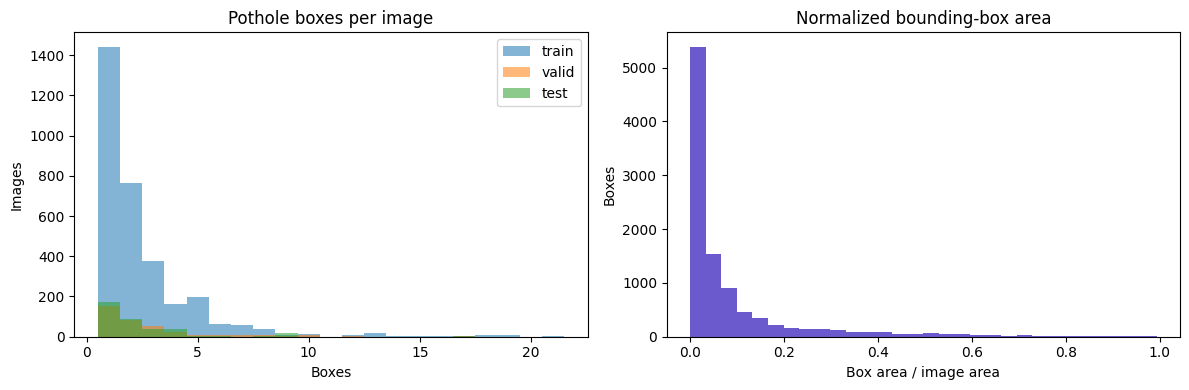

Images with no boxes: 0
Median normalized box area: 0.02832


In [7]:
boxes_per_image = labels_df.groupby(["split", "image"]).size().rename("boxes")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in SPLITS:
    split_counts = boxes_per_image.loc[split]
    axes[0].hist(split_counts, bins=range(1, 23), alpha=0.55, label=split, align="left")
axes[0].set(title="Pothole boxes per image", xlabel="Boxes", ylabel="Images")
axes[0].legend()
labels_df["normalized_area"] = labels_df["width"] * labels_df["height"]
axes[1].hist(labels_df["normalized_area"], bins=30, color="slateblue")
axes[1].set(title="Normalized bounding-box area", xlabel="Box area / image area", ylabel="Boxes")
plt.tight_layout()
plt.show()
print("Images with no boxes:", int((boxes_per_image == 0).sum()))
print("Median normalized box area:", round(float(labels_df["normalized_area"].median()), 5))


## 4. Model and training

We initialized YOLO11s from Ultralytics' pretrained `yolo11s.pt` weights and fine-tuned it for one pothole class. The detector predicts boxes at several feature-map scales to represent objects of different sizes.

The cleaned-v3 run used image size 640, batch size 16, random seed 0, a 100-epoch limit, and early-stopping patience 20. The best validation mAP50–95 was at epoch 63; training stopped after 83 epochs. The saved arguments record optimizer `auto`, so we do not claim a specific resolved optimizer.

In [8]:
# Write a machine-specific Ultralytics dataset configuration.
DATA_YAML = DATA_ROOT / "data.yaml"
DATA_YAML.write_text(
    f"path: {DATA_ROOT.as_posix()}\\n"
    "train: train/images\\n"
    "val: valid/images\\n"
    "test: test/images\\n"
    "nc: 1\\n"
    "names:\\n"
    "  0: pothole\\n",
    encoding="utf-8",
)
print(DATA_YAML.read_text())

path: /content/roadwatch_cleaned\ntrain: train/images\nval: valid/images\ntest: test/images\nnc: 1\nnames:\n  0: pothole\n


### Reproducible training configuration

The saved `best.pt` is the checkpoint used for the reported results. `RUN_TRAINING` remains false by default so the recorded experiment is preserved. The cell below retains the original training settings for a separate reproduction run, with a distinct run name and output directory.

In [9]:
RUN_TRAINING = False
RUN_NAME = "pothole_yolo11s_personal_v1"
RUNS_DIR = (DRIVE_ROOT / "RoadWatch_personal_training"
            if "DRIVE_ROOT" in globals() else Path("runs/training").resolve())

if RUN_TRAINING:
    import torch
    from ultralytics import YOLO

    if not torch.cuda.is_available():
        raise RuntimeError("Training is configured for a CUDA GPU. Set up a GPU runtime first.")
    run_dir = RUNS_DIR / RUN_NAME
    if run_dir.exists():
        raise FileExistsError(f"Choose a new RUN_NAME; {run_dir} already exists.")
    model = YOLO("yolo11s.pt")
    train_results = model.train(
        data=str(DATA_YAML), epochs=100, imgsz=640, batch=16,
        patience=20, device=0, seed=0,
        project=str(RUNS_DIR), name=RUN_NAME,
    )
    MODEL_PATH = Path(model.trainer.save_dir) / "weights" / "best.pt"
    print("Best checkpoint:", MODEL_PATH)
else:
    print("No additional training run was started; the recorded cleaned-v3 run is summarized below.")


No additional training run was started; the recorded cleaned-v3 run is summarized below.


### Training and evaluation results

The first row records the original epoch-63 validation metrics from the training artifacts. The remaining rows are from the separate CPU verification performed on 27 October 2026. The reproduced test metrics match the reported test values to two decimal places.

In [10]:
training_record = pd.DataFrame([
    {"source": "Original epoch 63 validation", "precision": 77.770, "recall": 66.653, "mAP50": 73.841, "mAP50-95": 41.528},
    {"source": "Reproduced validation", "precision": 77.813, "recall": 66.545, "mAP50": 73.820, "mAP50-95": 41.527},
    {"source": "Reproduced held-out test", "precision": 78.966, "recall": 67.946, "mAP50": 77.123, "mAP50-95": 48.406},
])
display(training_record.set_index("source").style.format("{:.3f}%"))


,precision,recall,mAP50,mAP50-95
source,,,,
Original epoch 63 validation,77.770%,66.653%,73.841%,41.528%
Reproduced validation,77.813%,66.545%,73.820%,41.527%
Reproduced held-out test,78.966%,67.946%,77.123%,48.406%


**Reading the metrics.** Precision is the share of predicted boxes that match a labeled pothole. Recall is the share of labeled potholes that the detector finds. mAP50 averages detection precision using an intersection-over-union match threshold of 0.50. mAP50–95 averages over stricter match thresholds from 0.50 through 0.95, so it also reflects how closely boxes fit.

The fixed checkpoint's reproduced test values agree with the previously reported values to two decimal places. The reproduction used CPU, Python 3.13.17, and PyTorch 2.14.1+cpu; the original run notes record a Tesla T4, Python 3.13.16, and PyTorch 2.11.0+cu130. Small validation differences can therefore be reported, but the hardware effect was not isolated experimentally. Test results should not be used to tune thresholds or choose a new model.


## 5. Saved-checkpoint evaluation

We retained the cleaned-v3 `best.pt` checkpoint in shared Drive rather than committing the weights to the repository. The setup cell verifies its documented SHA-256 and exposes it to the evaluation and inference sections. We used the test split for final evaluation after model selection.

In [11]:
if "MODEL_PATH" not in globals():
    MODEL_PATH = Path(os.environ.get("ROADWATCH_MODEL", "models/best.pt")).expanduser()
RUN_EVALUATION = False

if RUN_EVALUATION:
    from ultralytics import YOLO
    if not MODEL_PATH.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {MODEL_PATH}. Set ROADWATCH_MODEL to best.pt.")
    detector = YOLO(str(MODEL_PATH))
    for split in ("val", "test"):
        metrics = detector.val(
            data=str(DATA_YAML), split=split, imgsz=640,
            batch=16, device="cpu", workers=0,
            project=str(RUNS_DIR / "evaluation"), name=f"cleaned_v3_{split}", plots=True,
        )
        print(split, {
            "precision": round(metrics.box.mp, 4),
            "recall": round(metrics.box.mr, 4),
            "mAP50": round(metrics.box.map50, 4),
            "mAP50-95": round(metrics.box.map, 4),
        })
else:
    print("No new evaluation was run from this cell; the saved verification metrics are reported above.")


No new evaluation was run from this cell; the saved verification metrics are reported above.


Our saved test evaluation reported precision 78.97%, recall 67.95%, mAP50 77.12%, and mAP50–95 48.41%. Evaluation precision and recall summarize a precision-recall curve; they are not guaranteed to match the app wrapper's default confidence threshold of 0.25.


## 6. Image inference

We integrated the detector into an image-inference flow. Given a readable road image, it returns candidate pothole boxes and confidence scores. Confidence filtering controls which detections are shown; it does not confirm that a prediction is correct.

Saving road-pot.jpg to road-pot.jpg
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Detected boxes: 3


,class,confidence,x1,y1,x2,y2
0,pothole,0.711103,32.547157,88.862038,154.512711,119.647766
1,pothole,0.692115,41.274517,43.827110,105.390663,56.197262
2,pothole,0.272808,42.191494,76.178810,86.833160,84.371010


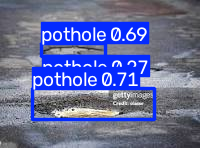

In [12]:
from pathlib import Path
import os
from PIL import Image

from google.colab import files
uploaded = files.upload()
IMAGE_FOR_PREDICTION = Path(next(iter(uploaded))) if uploaded else None
CONFIDENCE = 0.25
if "MODEL_PATH" not in globals():
    MODEL_PATH = Path(os.environ.get("ROADWATCH_MODEL", "models/best.pt")).expanduser()


def predict_road_image(image_path, confidence=0.25):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f"Image does not exist: {image_path}")
    if not 0.0 <= confidence <= 1.0:
        raise ValueError("confidence must be between 0 and 1")
    try:
        with Image.open(image_path) as image:
            image.verify()
    except Exception as error:
        raise ValueError(f"Input is not a readable image: {image_path}") from error
    if not MODEL_PATH.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {MODEL_PATH}")
    from ultralytics import YOLO
    detector = YOLO(str(MODEL_PATH))
    return detector.predict(source=str(image_path), conf=confidence, device="cpu", verbose=False)

if IMAGE_FOR_PREDICTION is not None and IMAGE_FOR_PREDICTION.is_file():
    predictions = predict_road_image(IMAGE_FOR_PREDICTION, CONFIDENCE)
    result = predictions[0]
    print("Detected boxes:", len(result.boxes))
    if result.boxes is not None and len(result.boxes):
        display(pd.DataFrame({
            "class": [result.names[int(c)] for c in result.boxes.cls.tolist()],
            "confidence": result.boxes.conf.tolist(),
            "x1": result.boxes.xyxy[:, 0].tolist(),
            "y1": result.boxes.xyxy[:, 1].tolist(),
            "x2": result.boxes.xyxy[:, 2].tolist(),
            "y2": result.boxes.xyxy[:, 3].tolist(),
        }))
    display(Image.fromarray(result.plot()[:, :, ::-1]))
else:
    print("No image was uploaded for this inference example.")


### What the output can and cannot explain

A prediction contains a class, a box, and a confidence score. The box shows the image region associated with a detection; the confidence score ranks how strongly the detector supports that candidate. This gives the user a visual explanation of the output, but it is not a full feature-attribution explanation of the neural network.

The project wrapper reports a count of predicted boxes; it does not verify them against ground truth. Because confidence threshold affects how many predictions are shown, threshold selection belongs on validation data rather than repeated test-set tuning.

## 7. Limitations and next steps

- The dataset has no empty-label negative images, so it cannot by itself establish false-positive behavior on roads without potholes.
- Similarity checks reduce known overlap but cannot prove that all images come from separate road scenes or journeys.
- Visual review showed missed small potholes, extra detections, and loose or overlapping boxes.
- The recorded CPU image timing is not a phone benchmark or an end-to-end application latency measurement.
- Android integration, mobile export, GPS localization, and pothole severity estimation are outside the work demonstrated in this repository.

For future evaluation, we identified a need for independently sourced road journeys, roads without potholes, consistent annotation, predefined lighting and size subgroups, and a final test set kept out of model and threshold selection.

## 8. Summary

We used cleaned-v3 data to fine-tune a pretrained YOLO11s detector for one pothole class. Our workflow checked YOLO labels, preserved separate validation and test partitions, evaluated the fixed checkpoint with object-detection metrics, and demonstrated image inference with boxes and confidence scores.

The notebook records the original GPU training results separately from the later CPU reproduction, with dataset and checkpoint hashes preserved for provenance.

## Group collaboration

The screenshot records our group together during a walkthrough of the YOLO11s notebook.

![Group collaboration during the notebook walkthrough](group-img.jpeg)